# Machine learning: role-family classifier

**Question:** given a skill profile, which data role family does a job posting belong to? This lets the interview coach position a candidate's CV against the market.

**Data:** `lukebarousse/data_jobs` 2023, read from PostgreSQL. **Features:** the 58 skills of the coach's taxonomy (multi-hot) + number of skills: exactly what the coach can extract from a CV (train/serve consistency). Job titles are **never** used (the role label was derived from titles by the dataset author: leakage).

In [1]:
import json, os, sys
import joblib, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, os.path.abspath('..'))
from market.ml.train import RESULTS_DIR, predict_roles
from market.ml.figures import FIG_DIR
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
role = json.loads((RESULTS_DIR / 'role_model.json').read_text())
sen = json.loads((RESULTS_DIR / 'seniority_experiment.json').read_text())
{k: role[k] for k in ['rows','features','train_rows','test_rows','train_companies','test_companies','tuning_rows']}

{'rows': 641060,
 'features': 59,
 'train_rows': 508332,
 'test_rows': 132728,
 'train_companies': 93083,
 'test_companies': 23271,
 'tuning_rows': 119999}

## 1. Split, class balance and baselines
Company-grouped 80/20 split (`GroupShuffleSplit`): no company appears in both sets, so templated postings from one employer cannot inflate the test score. Classes are imbalanced, so **macro-F1** is the main metric.

In [2]:
pd.DataFrame({'train': role['class_distribution_train'], 'test': role['class_distribution_test']}).assign(
    test_share_pct=lambda d: (d.test / d.test.sum() * 100).round(2)).sort_values('train', ascending=False)

,train,test,test_share_pct
Data Engineer,163153,43455,32.74
Data Analyst,137484,35955,27.09
Data Scientist,136637,36260,27.32
Software Engineer,28678,6451,4.86
Business Analyst,26291,6791,5.12
Machine Learning Engineer,9550,2264,1.71
Cloud Engineer,6539,1552,1.17


In [3]:
pd.DataFrame({k: {m: v[m] for m in ['accuracy','balanced_accuracy','macro_f1','weighted_f1']} for k, v in role['baselines'].items()}).T

,accuracy,balanced_accuracy,macro_f1,weighted_f1
most_frequent,0.3274,0.1429,0.0705,0.1615
stratified,0.2565,0.1422,0.1421,0.2579


## 2. Model selection (cross-validation on the training set only)
StratifiedGroupKFold (3 folds) on a stratified subsample of the training set; grid search per candidate; selection by mean CV macro-F1.

In [4]:
pd.DataFrame([{'model': k, 'best_params': v['best_params'], 'cv_macro_f1': f"{v['cv_macro_f1_mean']:.4f} ± {v['cv_macro_f1_std']:.4f}"}
              for k, v in role['candidates'].items()])

,model,best_params,cv_macro_f1
0,logistic_regression,"{'logisticregression__C': 0.01, 'logisticregre...",0.3529 ± 0.0048
1,decision_tree,"{'class_weight': None, 'max_depth': 20, 'min_s...",0.3438 ± 0.0020
2,hist_gradient_boosting,"{'class_weight': None, 'learning_rate': 0.1, '...",0.3875 ± 0.0027


In [5]:
for name, v in role['candidates'].items():
    print(name); display(pd.DataFrame(v['cv_grid']).sort_values('macro_f1', ascending=False).head(4))

logistic_regression


,params,macro_f1
1,"{'logisticregression__C': 0.01, 'logisticregre...",0.3529
3,"{'logisticregression__C': 0.1, 'logisticregres...",0.3526
5,"{'logisticregression__C': 1.0, 'logisticregres...",0.3526
4,"{'logisticregression__C': 1.0, 'logisticregres...",0.3486


decision_tree


,params,macro_f1
4,"{'class_weight': None, 'max_depth': 20, 'min_s...",0.3438
9,"{'class_weight': 'balanced', 'max_depth': 14, ...",0.3310
2,"{'class_weight': None, 'max_depth': 14, 'min_s...",0.3306
8,"{'class_weight': 'balanced', 'max_depth': 14, ...",0.3291


hist_gradient_boosting


,params,macro_f1
1,"{'class_weight': None, 'learning_rate': 0.1, '...",0.3875
2,"{'class_weight': None, 'learning_rate': 0.2, '...",0.3854
5,"{'class_weight': 'balanced', 'learning_rate': ...",0.3827
4,"{'class_weight': 'balanced', 'learning_rate': ...",0.3816


## 3. Test-set evaluation (used once, all candidates reported)

In [6]:
pd.DataFrame({k: {m: v['test'][m] for m in ['accuracy','balanced_accuracy','macro_f1','weighted_f1']} for k, v in role['candidates'].items()}).T

,accuracy,balanced_accuracy,macro_f1,weighted_f1
logistic_regression,0.4386,0.4687,0.3399,0.4773
decision_tree,0.6208,0.3527,0.3575,0.5937
hist_gradient_boosting,0.6387,0.3805,0.3929,0.6141


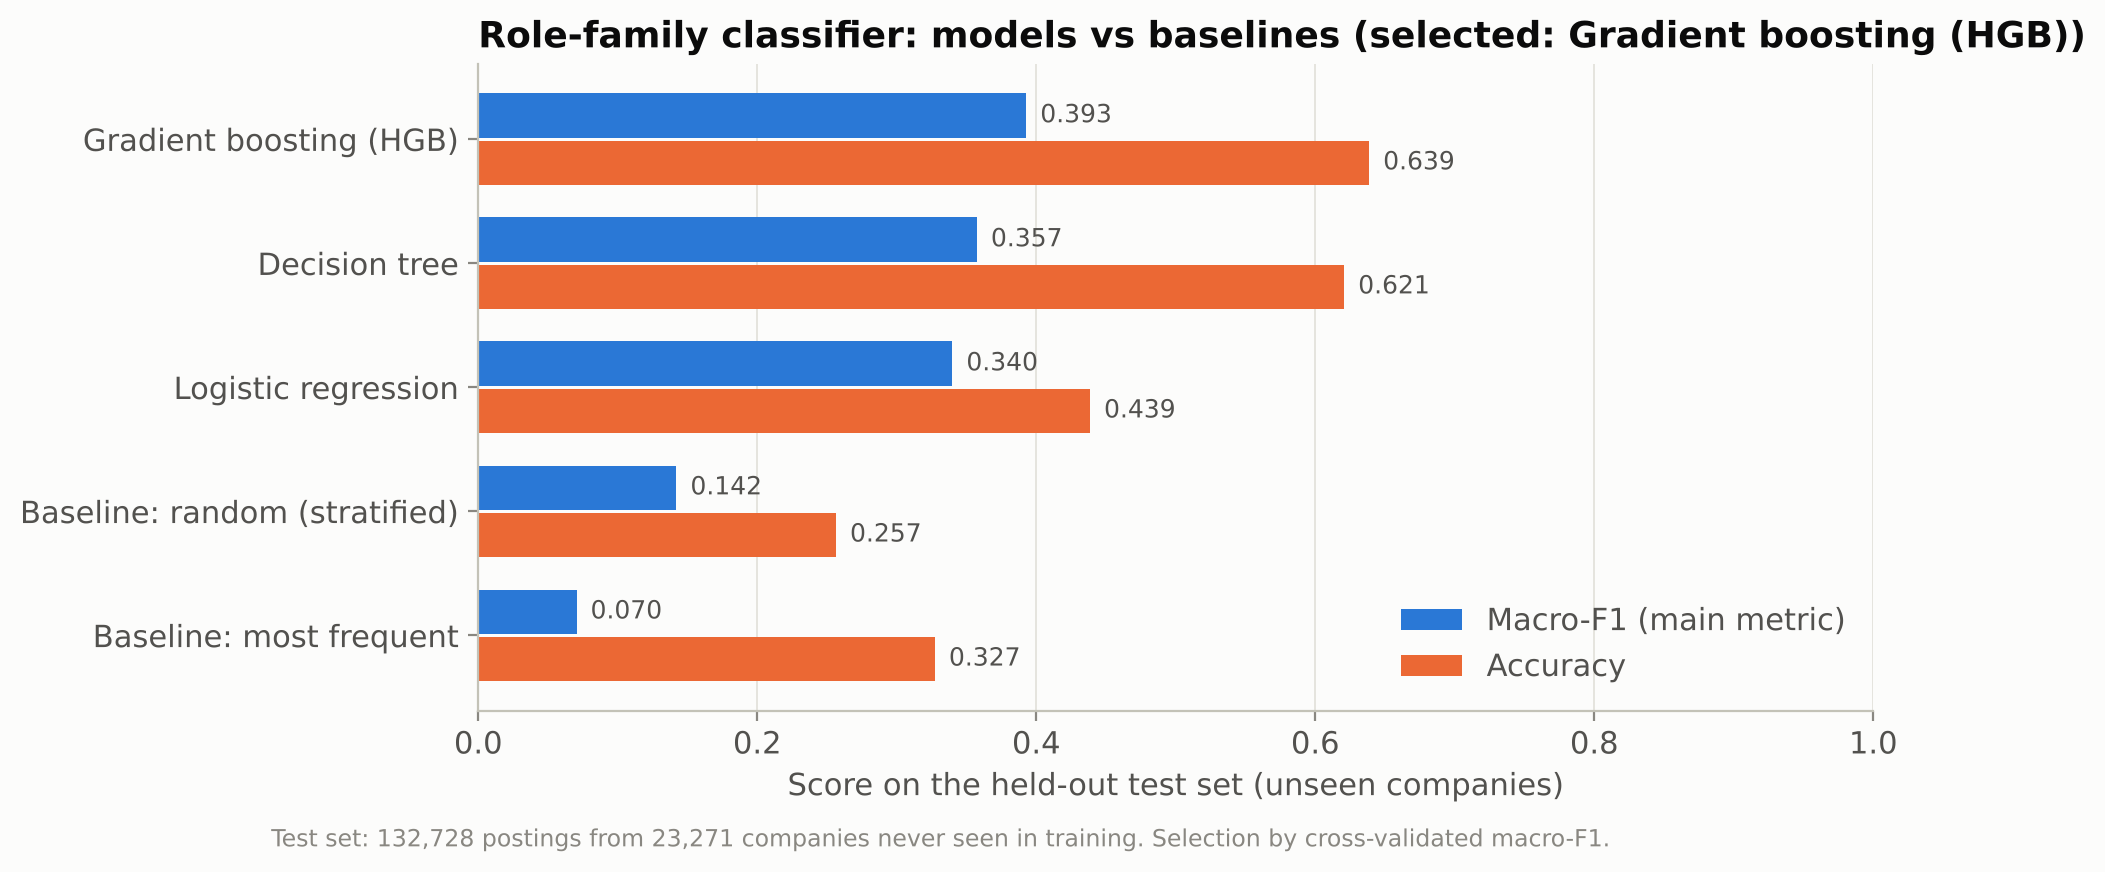

Selected: hist_gradient_boosting - highest cross-validated macro-F1 on the training data (test set not used for selection)


In [7]:
display(Image(str(FIG_DIR / 'ML_model_comparison.png'), width=750))
print('Selected:', role['selected_model'], '-', role['selection_rule'])

In [8]:
best = role['candidates'][role['selected_model']]['test']
pd.DataFrame(best['per_class']).T[['precision','recall','f1-score','support']]

,precision,recall,f1-score,support
Business Analyst,0.4744,0.0054,0.0108,6791.0
Cloud Engineer,0.3672,0.0909,0.1457,1552.0
Data Analyst,0.5895,0.7072,0.6430,35955.0
Data Engineer,0.7049,0.7740,0.7378,43455.0
Data Scientist,0.6331,0.6360,0.6346,36260.0
Machine Learning Engineer,0.4663,0.1038,0.1698,2264.0
Software Engineer,0.4978,0.3465,0.4086,6451.0


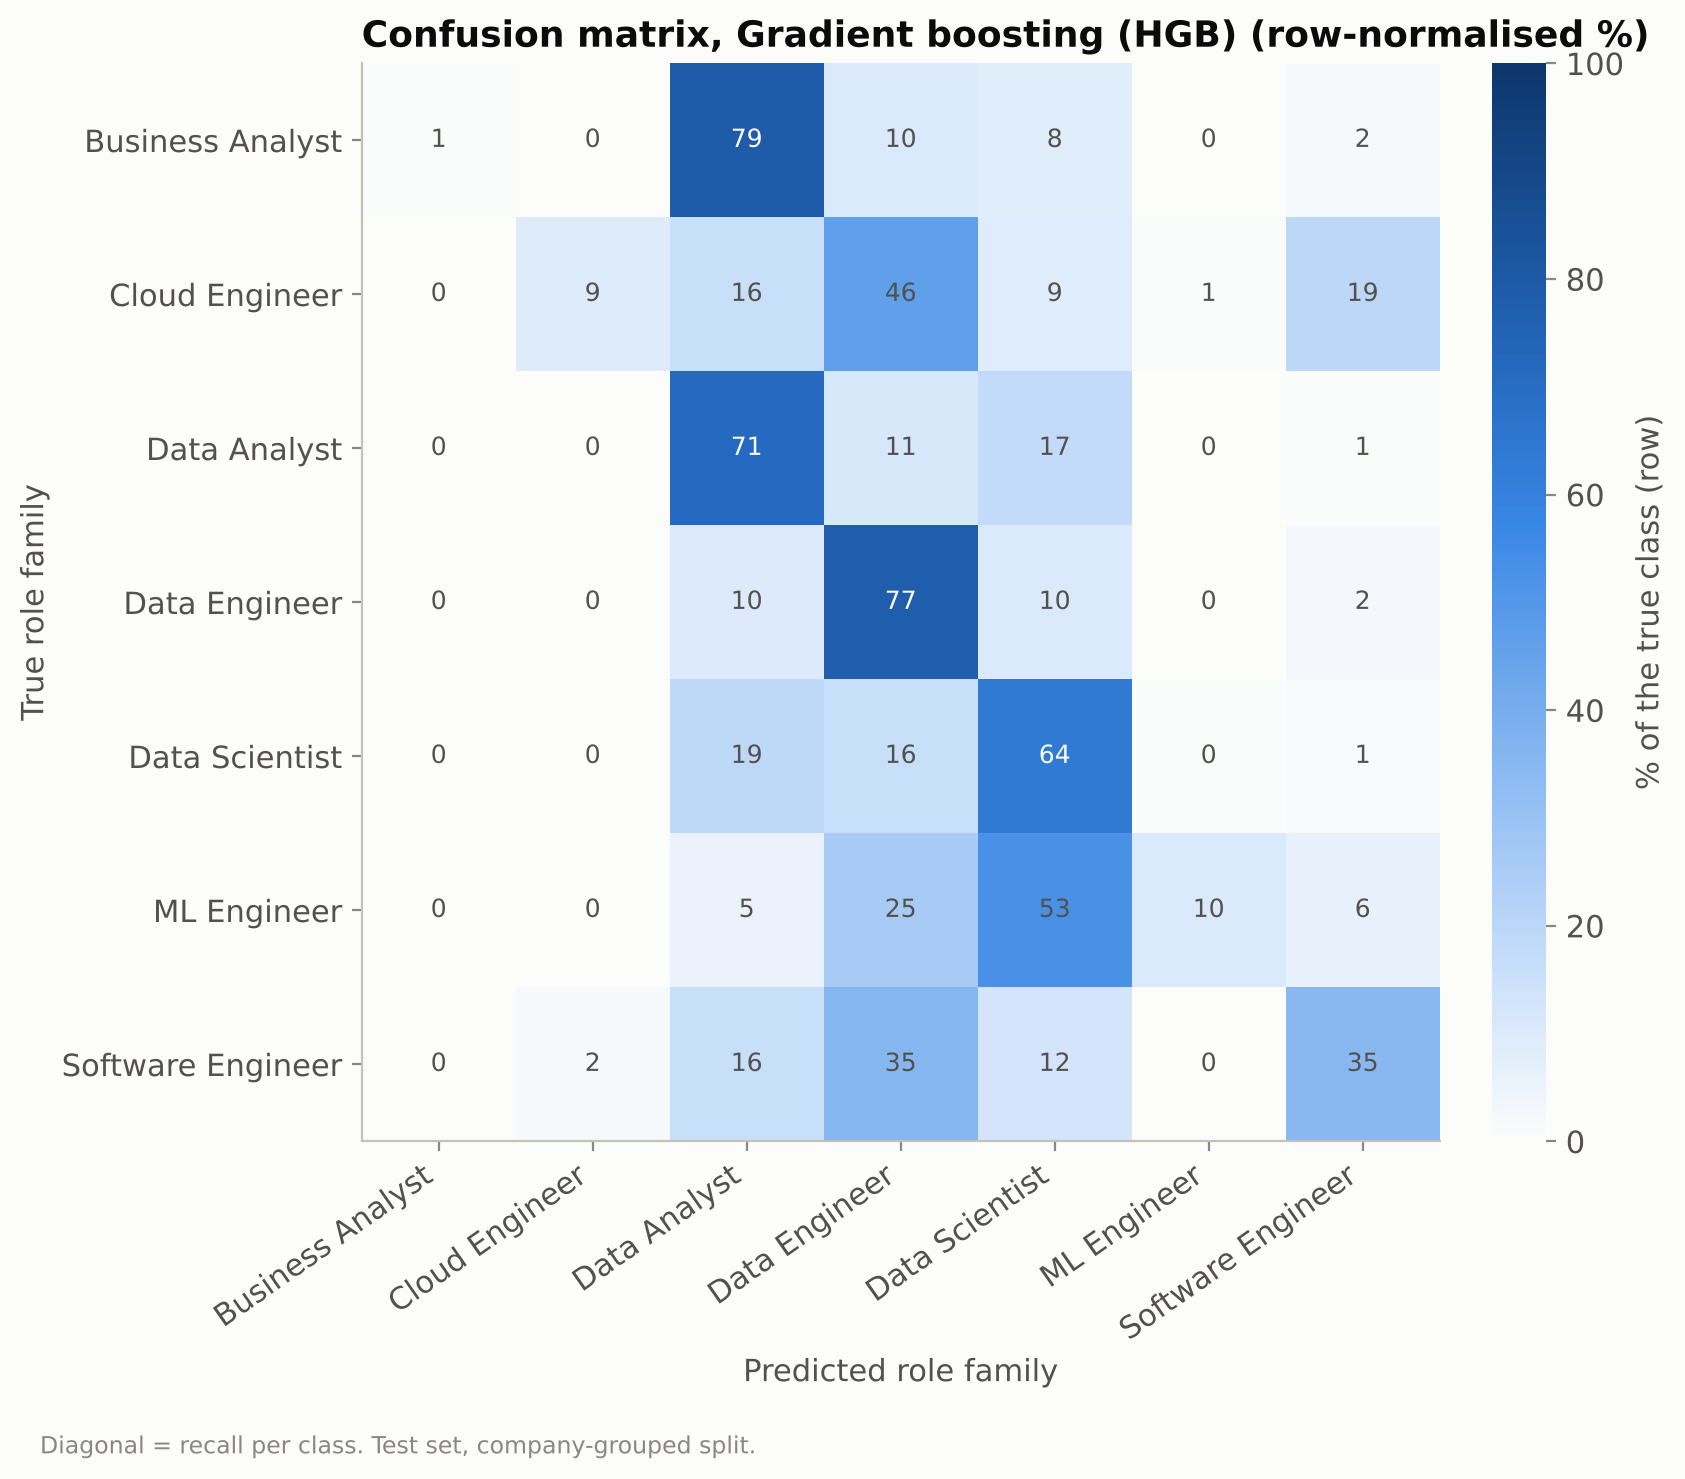

In [9]:
display(Image(str(FIG_DIR / 'ML_confusion_matrix.png'), width=650))

## 4. Interpretation

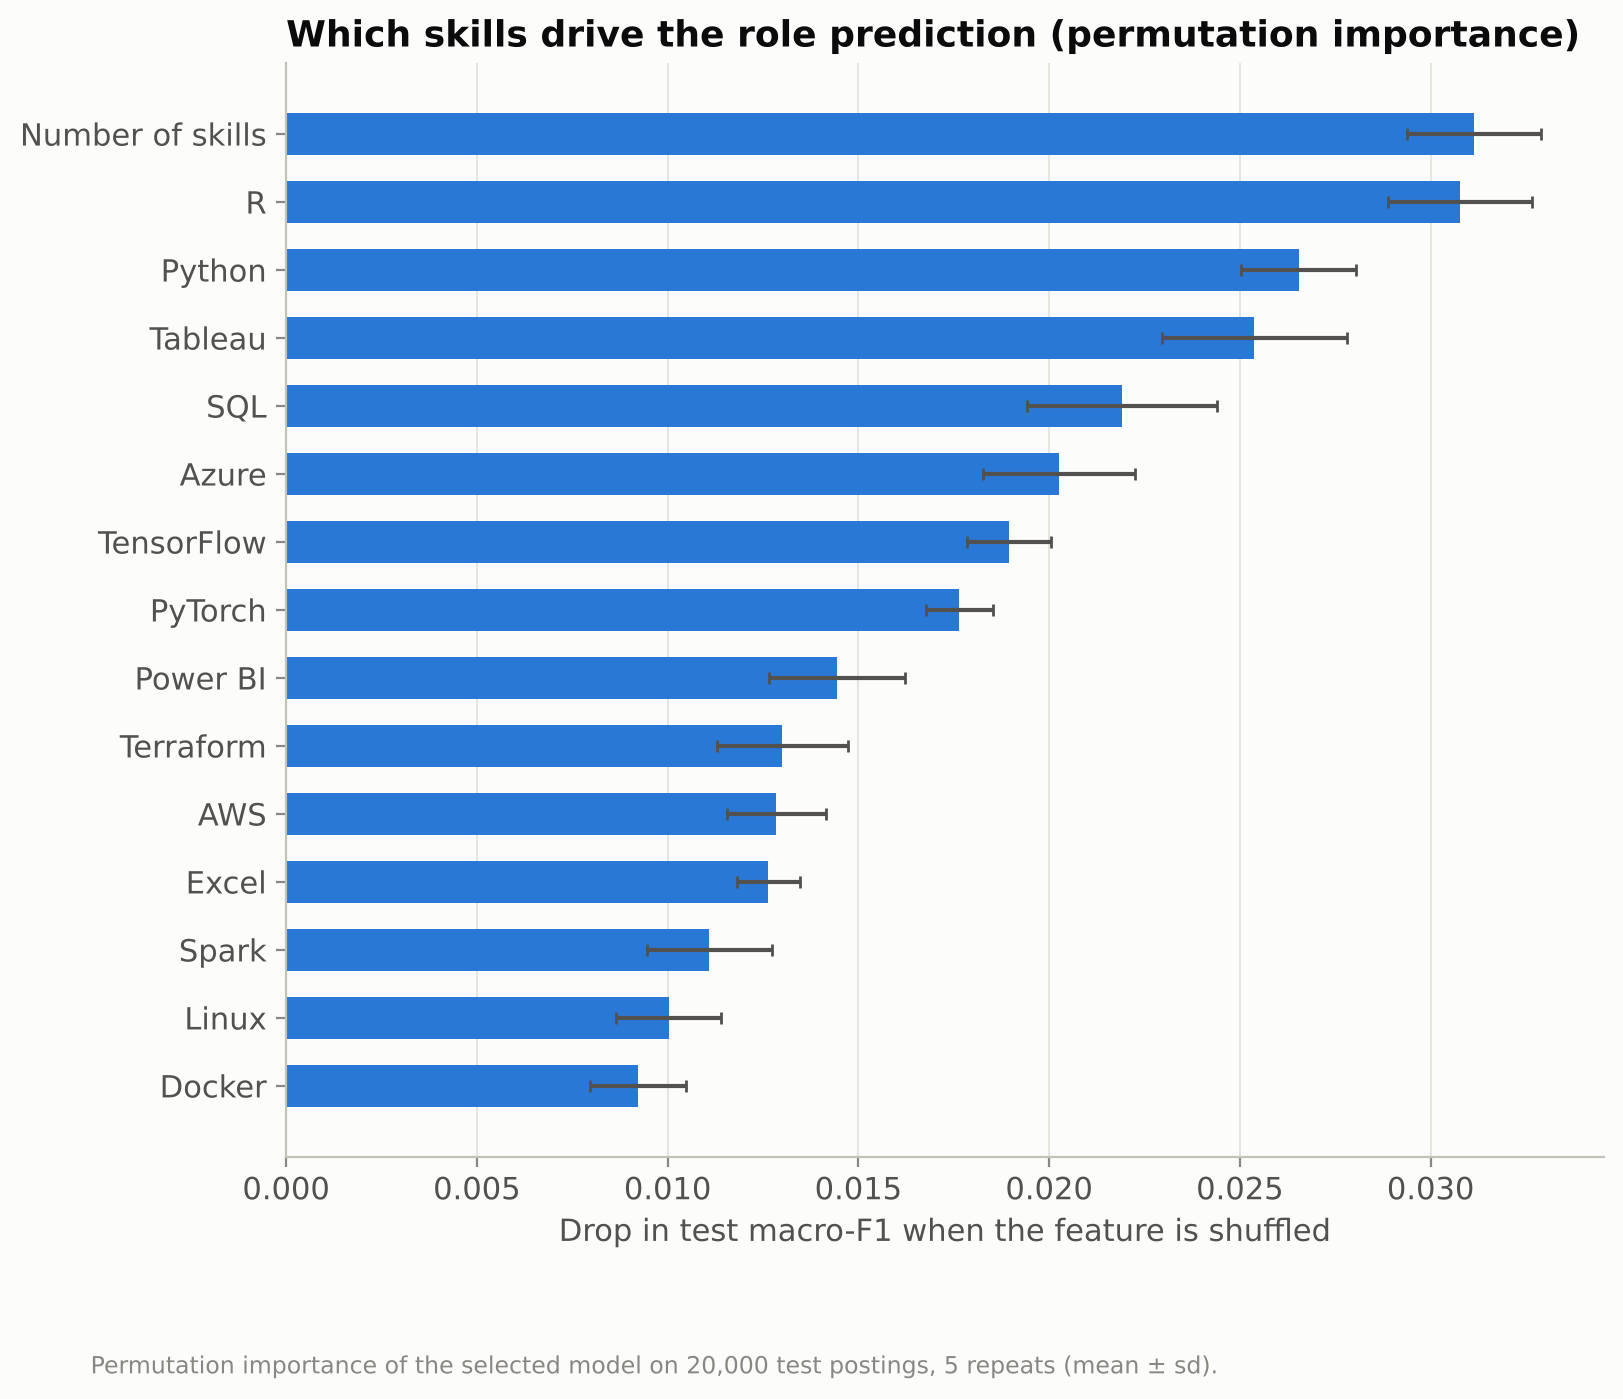

In [10]:
display(Image(str(FIG_DIR / 'ML_feature_importance.png'), width=650))

In [11]:
pd.DataFrame({cls: {'most positive': ', '.join(f'{f} ({c:+.2f})' for f, c in d['positive']),
                     'most negative': ', '.join(f'{f} ({c:+.2f})' for f, c in d['negative'])}
              for cls, d in role['logistic_top_features'].items()}).T

,most positive,most negative
Business Analyst,"Excel (+0.50), Tableau (+0.33), Power BI (+0.3...","Python (-0.34), Spark (-0.23), AWS (-0.21), Az..."
Cloud Engineer,"Azure (+0.31), Terraform (+0.24), Linux (+0.22...","SQL (-0.31), Python (-0.29), R (-0.18), Data V..."
Data Analyst,"Excel (+0.41), SQL (+0.33), Tableau (+0.33), P...","Azure (-0.24), AWS (-0.22), Java (-0.21), Kube..."
Data Engineer,"Spark (+0.27), SQL (+0.26), Azure (+0.20), Air...","Excel (-0.34), R (-0.31), TensorFlow (-0.16), ..."
Data Scientist,"R (+0.49), Python (+0.43), TensorFlow (+0.21),...","Terraform (-0.19), Kafka (-0.14), Java (-0.13)..."
Machine Learning Engineer,"Python (+0.47), PyTorch (+0.32), TensorFlow (+...","Tableau (-0.35), SQL (-0.33), Power BI (-0.27)..."
Software Engineer,"Java (+0.22), Linux (+0.16), Kubernetes (+0.14...","R (-0.36), Excel (-0.22), Python (-0.22), SQL ..."


## 5. Using the saved model on CV skill lists
The coach extracts skills from a CV with the same taxonomy; `predict_roles` uses the same `build_features` function as training. The skill lists below come from the project's **fictional** example and evaluation CVs (extracted by the coach's real extractor).

In [12]:
from app.matching.skills import extract_skills
bundle = joblib.load(os.path.join('..', 'models', 'role_classifier.joblib'))
cvs = {name: extract_skills(open(os.path.join('..', 'evaluation', 'data', f'{name}.txt')).read())
       for name in ['cv_ml_engineer', 'cv_backend_developer', 'cv_marketing_coordinator']}
pd.DataFrame([{'cv': n, 'skills_used_by_model': ', '.join(s for s in skills if s in bundle['feature_skills']),
               'top_3_roles': '; '.join(f"{p['role_family']} {p['probability']:.0%}" for p in predict_roles(bundle, skills))}
              for n, skills in cvs.items()])

,cv,skills_used_by_model,top_3_roles
0,cv_ml_engineer,"Python, SQL, Bash, Transformers, PyTorch, scik...",Machine Learning Engineer 66%; Data Scientist ...
1,cv_backend_developer,"Python, PostgreSQL, Redis, Elasticsearch, Fast...",Software Engineer 92%; Data Engineer 4%; Data ...
2,cv_marketing_coordinator,Excel,Data Analyst 61%; Business Analyst 20%; Data S...


## 6. Secondary experiment: senior vs non-senior
Same features + role one-hot, Data Analyst/Engineer/Scientist only, company-grouped split, class_weight='balanced'. Phase 4 showed skill differences between senior and non-senior postings are small, so a weak model is expected.

In [13]:
pd.DataFrame({k: {m: v[m] for m in ['best_params','cv_roc_auc','test_roc_auc','test_average_precision','test_balanced_accuracy','test_f1_senior']}
              for k, v in sen['models'].items()}).T.assign(baseline_average_precision=sen['baseline']['average_precision'])

,best_params,cv_roc_auc,test_roc_auc,test_average_precision,test_balanced_accuracy,test_f1_senior,baseline_average_precision
logistic_regression,{'logisticregression__C': 0.01},0.5957,0.5986,0.2351,0.5689,0.3184,0.1785
hist_gradient_boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.604,0.6251,0.267,0.5881,0.3372,0.1785


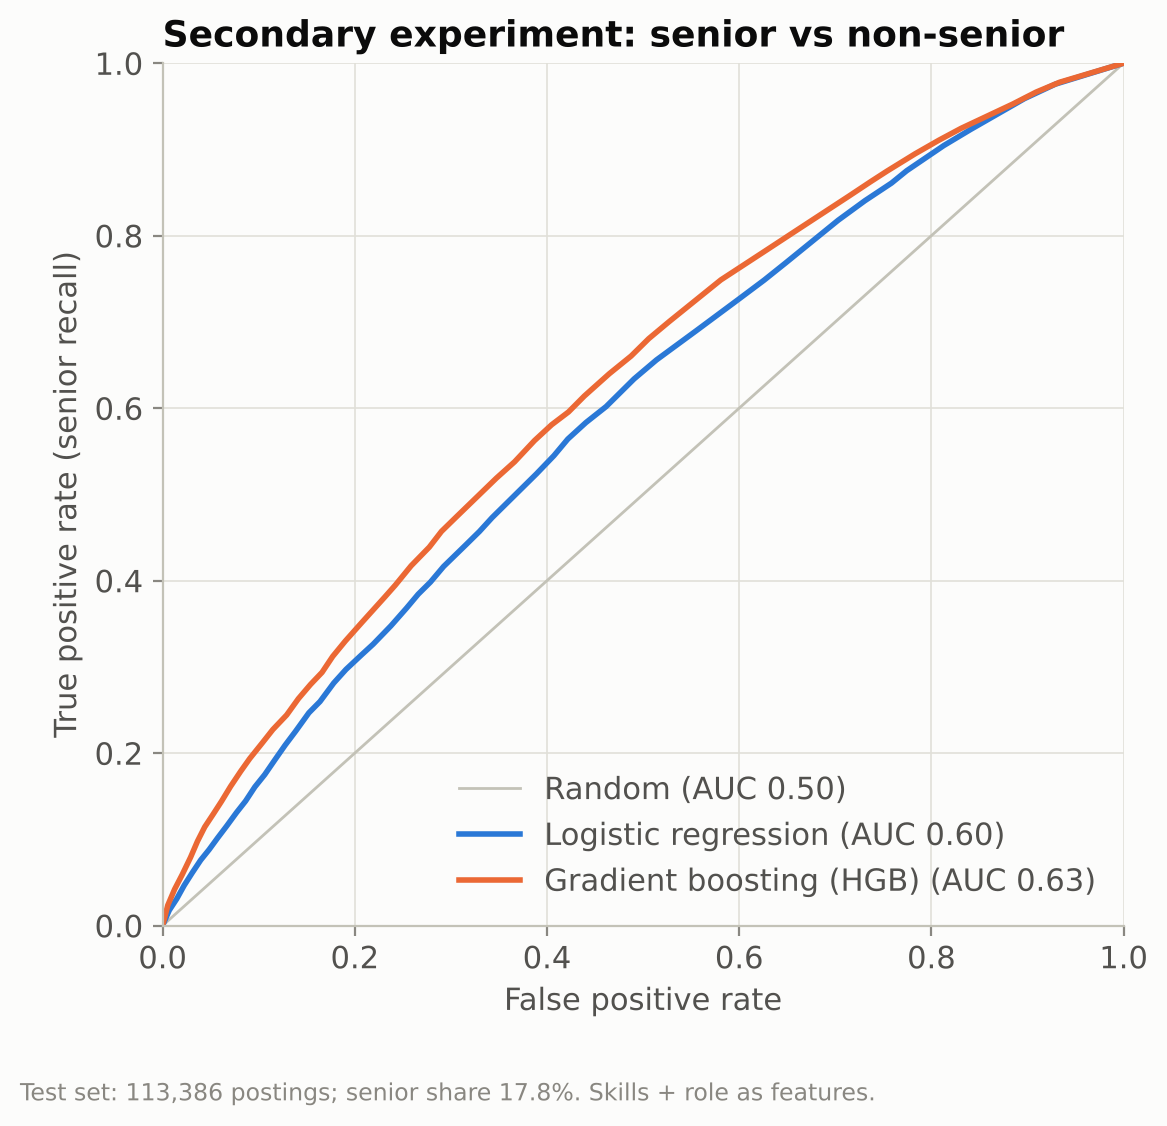

In [14]:
display(Image(str(FIG_DIR / 'ML_seniority_roc.png'), width=450))

## 7. Limitations
- Labels come from the dataset author's title classifier (`job_title_short`), not from human annotation.
- Skills were keyword-extracted by the author; only the 58 coach-taxonomy skills are used, so specialised tools outside the taxonomy are invisible to the model.
- 2023 postings, data roles only, collector's search locations: the model describes this market, not every market.
- A CV is not a job posting: predictions on CVs are a positioning signal, not a ground-truth label.
- Hyper-parameters were tuned on a subsample (compute budget); results could improve slightly with full-data tuning.